# EDA — Enchentes em Porto Alegre (INCT SiMAI + ANA)
Fase 2 — Coleta, Preparação e Análise de Dados, PUCRS 2026/2.

Rode antes: `coleta_ana.py`, `limpa_inct.py`, `processa_ana.py`.

**Atenção:** os números de pessoas e prédios são **estimativas de uma simulação**, não previsões nem contagens oficiais.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
AZUL, CINZA, TINTA = '#2a6f97', '#8a8f98', '#222831'
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e8eb', 'axes.axisbelow': True, 'font.size': 10,
                     'axes.titlelocation': 'left', 'axes.titleweight': 'bold'})
P = '../dados/processados/'
inct = pd.read_csv(P + 'inct_longo_limpo.csv')
ana = pd.read_csv(P + 'ana_diario.csv', parse_dates=['data'])
h = pd.read_csv(P + 'enchente_2024_horario.csv', parse_dates=['data_hora'])
cidade = inct.groupby('nivel_m').agg(pessoas=('affected_population', 'sum'), pessoas_orig=('affected_population_original', 'sum'),
                                      predios=('affected_buildings', 'sum'))
cidade['bairros'] = inct[inct.affected_buildings > 0].groupby('nivel_m').bairro.nunique()
print(inct.shape, ana.shape, h.shape)

(6674, 11) (4037, 7) (264, 9)


## Tela 1 — Simulação do INCT
### 1. Prédios afetados: original × corrigido

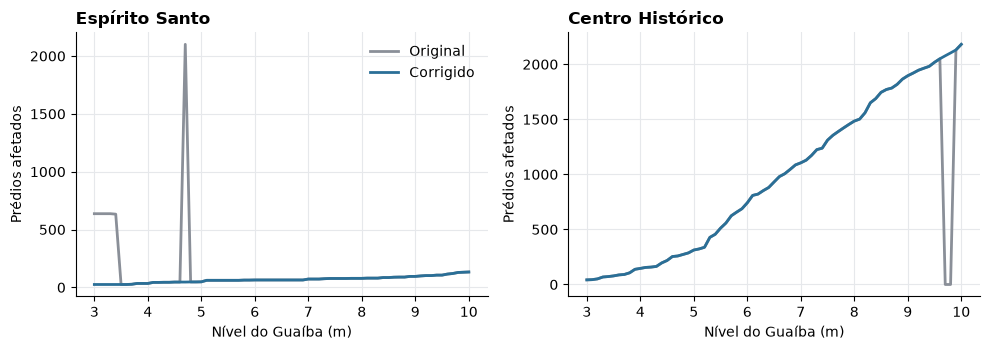

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, b in zip(ax, ['Espírito Santo', 'Centro Histórico']):
    d = inct[inct.bairro == b]
    a.plot(d.nivel_m, d.affected_buildings_original, color=CINZA, lw=2, label='Original')
    a.plot(d.nivel_m, d.affected_buildings, color=AZUL, lw=2, label='Corrigido')
    a.set(title=b, xlabel='Nível do Guaíba (m)', ylabel='Prédios afetados')
ax[0].legend(frameon=False); plt.tight_layout()

Prédios afetados não podem diminuir quando o rio sobe. Aqui o Espírito Santo tem um bloco alto entre 3,0 e 3,4 m e um salto em 4,7 m; o Centro Histórico zera em 9,7 e 9,8 m. Corrigimos 17 valores em 5 bairros mantendo a maior sequência não decrescente de cada bairro e interpolando o restante. No Espírito Santo o bloco inicial é incerto: fica o aviso no relatório.

### 2. Quanto o arredondamento para cima infla a população afetada

,affected_buildings_original,total_buildings,percentage_original,percentage,affected_population_original,affected_population
5256,1,15906,1,0.01,314,2


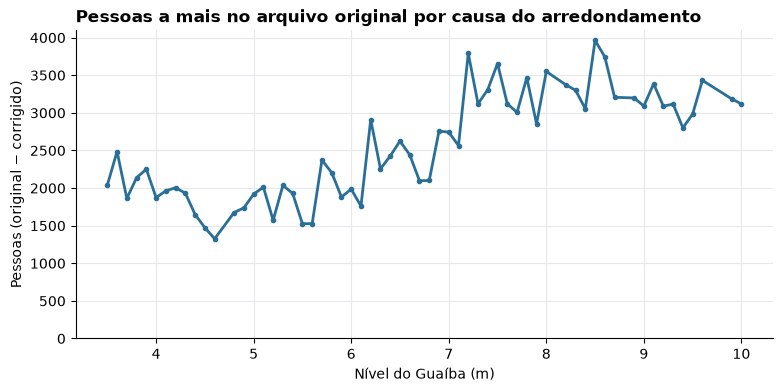

In [3]:
d = cidade.pessoas_orig - cidade.pessoas
ok = ~d.index.isin([8.8, 9.7, 9.8, 8.1, 4.7, 3.0, 3.1, 3.2, 3.3, 3.4])
fig, ax = plt.subplots()
ax.plot(d.index[ok], d[ok], color=AZUL, lw=2, marker='o', ms=3)
ax.set(title='Pessoas a mais no arquivo original por causa do arredondamento', xlabel='Nível do Guaíba (m)', ylabel='Pessoas (original − corrigido)')
ax.set_ylim(bottom=0)
ex = inct[(inct.bairro=='Santa Tereza')&(inct.nivel_m==3.2)][['affected_buildings_original','total_buildings','percentage_original','percentage','affected_population_original','affected_population']]
ex

`percentage` vem como inteiro arredondado para cima, e `affected_population` herda isso. Em Santa Tereza a 3,2 m, 1 prédio em 15.906 vira 1%, ou 314 pessoas, quando o valor proporcional seria 2. Recalculamos o percentual exato. Os níveis com prédios corrigidos ficam de fora deste gráfico, para isolar só o efeito do arredondamento.

### 3. Curva da população afetada na cidade

,pessoas,pessoas_orig,predios,bairros
nivel_m,,,,
3.0,32112,34605,14647,24
4.0,83097,84970,32776,33
5.0,125692,127611,49623,36
5.4,139179,141108,55170,36
6.0,163825,165811,64486,39
8.0,218349,221899,83009,49
10.0,271875,274993,101211,54


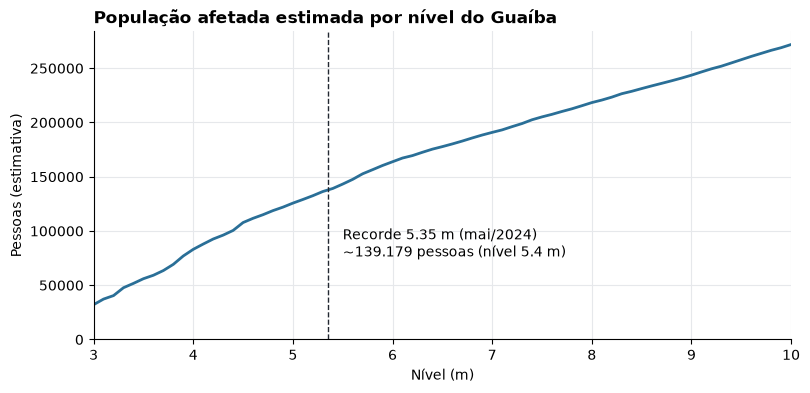

In [4]:
fig, ax = plt.subplots()
ax.plot(cidade.index, cidade.pessoas, color=AZUL, lw=2)
p = cidade.pessoas.loc[5.4]
ax.axvline(5.35, color=TINTA, lw=1, ls='--'); ax.annotate(f'Recorde 5,35 m (mai/2024)\n~{p:,.0f} pessoas (nível 5,4 m)'.replace(',', '.'), (5.35, p), (5.5, p*0.55))
ax.set(title='População afetada estimada por nível do Guaíba', xlabel='Nível (m)', ylabel='Pessoas (estimativa)', xlim=(3, 10), ylim=(0, None))
cidade.loc[[3.0, 4.0, 5.0, 5.4, 6.0, 8.0, 10.0]]

A curva sobe quase em linha reta, sem um nível em que a cidade "vire" de repente. Isso é útil para comunicar risco: cada 10 cm conta. Ela já começa em 32.112 pessoas a 3,0 m porque bairros baixos, como o Arquipélago, aparecem quase todos afetados desde o início da simulação.

### 4. Bairros mais afetados no nível do recorde

,bairro,affected_population,percentage
5491,Sarandi,24391,47.32
1941,Farrapos,17591,100.00
3716,Menino Deus,15707,56.18
2367,Humaitá,12744,100.00
1444,Cidade Baixa,7177,55.15


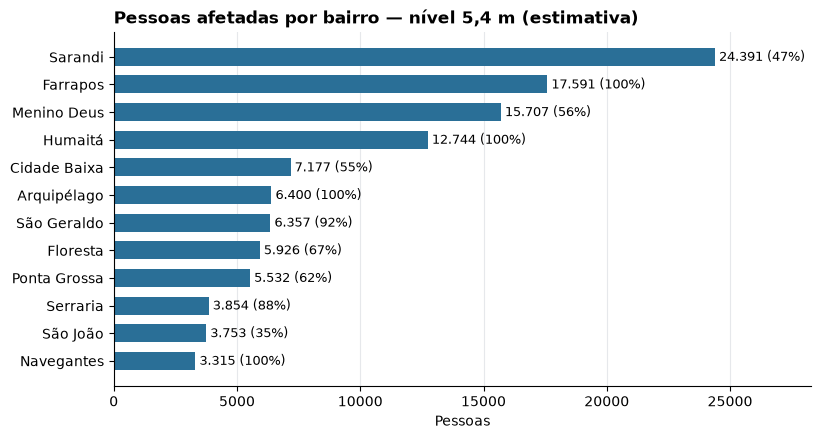

In [5]:
n = inct[inct.nivel_m == 5.4].nlargest(12, 'affected_population').sort_values('affected_population')
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(n.bairro, n.affected_population, color=AZUL, height=.65)
for y, v, pc in zip(n.bairro, n.affected_population, n.percentage): ax.text(v, y, f' {v:,.0f} ({pc:.0f}%)'.replace(',', '.'), va='center', fontsize=9)
ax.set(title='Pessoas afetadas por bairro — nível 5,4 m (estimativa)', xlabel='Pessoas'); ax.grid(axis='y', visible=False); ax.margins(x=.16)
n[['bairro', 'affected_population', 'percentage']].iloc[::-1].head(5)

Sarandi lidera em pessoas (24.391), mas com 47% dos prédios afetados; Farrapos e Humaitá chegam a 100%. Por isso a Tela 1 mostra os dois recortes: quantas pessoas e qual fração dos prédios do bairro.

### 5. Bairros atingidos por nível

nivel_m
3.0     24
4.0     33
5.4     36
7.0     45
10.0    54
Name: bairros, dtype: int64

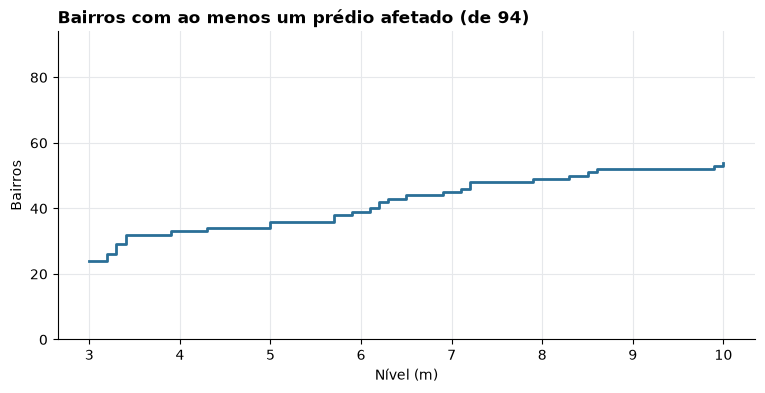

In [6]:
fig, ax = plt.subplots()
ax.step(cidade.index, cidade.bairros, color=AZUL, lw=2, where='post')
ax.set(title='Bairros com ao menos um prédio afetado (de 94)', xlabel='Nível (m)', ylabel='Bairros', ylim=(0, 94))
cidade.bairros.loc[[3.0, 4.0, 5.4, 7.0, 10.0]]

De 3,0 a 4,0 m entram 9 bairros (24 para 33). Entre 4,0 e 5,4 m entram só 3, e depois o número volta a crescer, chegando a 54 em 10 m. Na faixa da cheia de 2024, a água avança mais dentro dos mesmos bairros do que para bairros novos.

## Tela 2 — Nível do Guaíba (ANA)
### 6. Linha do tempo do nível

                          min        max  count
estacao                                        
Cais Mauá          2014-07-29 2026-10-28   3632
Usina do Gasômetro 2024-05-03 2025-06-11    405


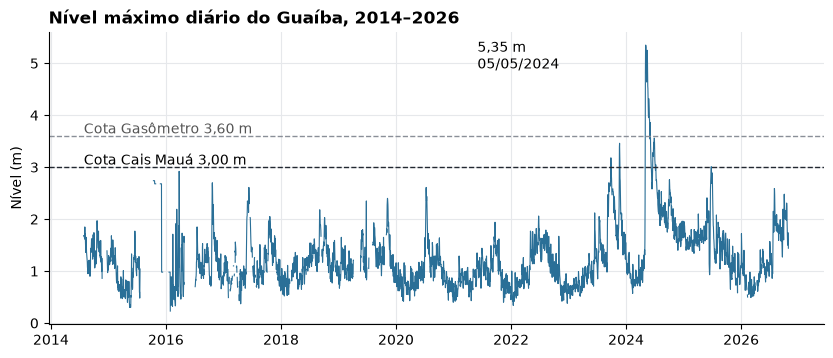

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.8))
serie = ana.set_index('data').nivel_max_cm.asfreq('D')/100  # lacunas ficam em branco
ax.plot(serie.index, serie, color=AZUL, lw=.8)
ax.axhline(3.0, color=TINTA, lw=1, ls='--'); ax.text(ana.data.min(), 3.05, 'Cota Cais Mauá 3,00 m')
ax.axhline(3.6, color=CINZA, lw=1, ls='--'); ax.text(ana.data.min(), 3.65, 'Cota Gasômetro 3,60 m', color='#555')
ax.annotate('5,35 m\n05/05/2024', (pd.Timestamp('2024-05-05'), 5.35), (pd.Timestamp('2021-06-01'), 4.9))
ax.set(title='Nível máximo diário do Guaíba, 2014–2026', ylabel='Nível (m)')
print(ana.groupby('estacao').data.agg(['min', 'max', 'count']))

A série combina Cais Mauá e Gasômetro. O Cais Mauá parou em 02/05/2024 às 23h15, e o Gasômetro cobre o período até 11/06/2025. Os referenciais diferem, então comparações finas entre os dois períodos pedem cuidado. Removemos 123 leituras do Cais Mauá como picos falsos do sensor, entre elas o suposto 3,90 m de 2017. Também descartamos os dias em que o sensor ficou travado, como em 2015–16, e as lacunas aparecem em branco.

### 7. Dias acima da cota de inundação por ano

,dias,dias_com_dado
data,,
2014,0,126
2015,0,232
2016,0,276
2017,0,310
2018,0,347
2019,0,275
2020,0,366
2021,0,365
2022,0,365


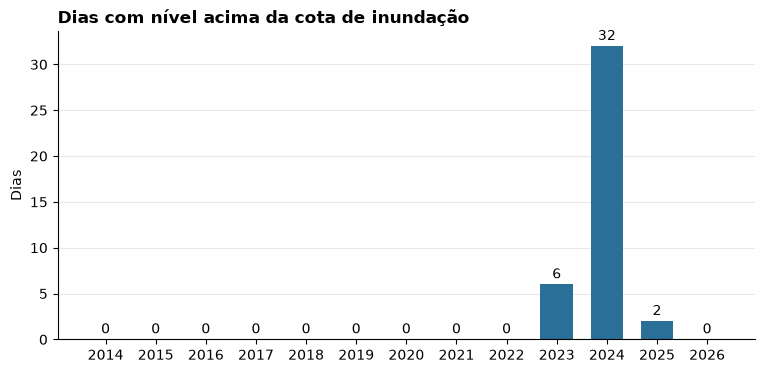

In [8]:
d = ana.groupby(ana.data.dt.year).agg(dias=('acima_cota', 'sum'), dias_com_dado=('data', 'count'))
fig, ax = plt.subplots()
b = ax.bar(d.index, d.dias, color=AZUL, width=.65)
ax.bar_label(b, padding=2); ax.set(title='Dias com nível acima da cota de inundação', ylabel='Dias', xticks=d.index); ax.grid(axis='x', visible=False)
d

Até 2022 nenhum dia passou da cota nesta série. A concentração em 2023–2025 é forte, mas a série só tem 12 anos e 2014–2016 têm muitas lacunas. Não dá para concluir tendência. Cada dia usa a cota da estação em operação.

### 8. Enchente de maio de 2024, hora a hora

data_hora    2024-05-05 05:00:00
nivel_m                     5.35
estacao       Usina do Gasômetro
Name: 101, dtype: object

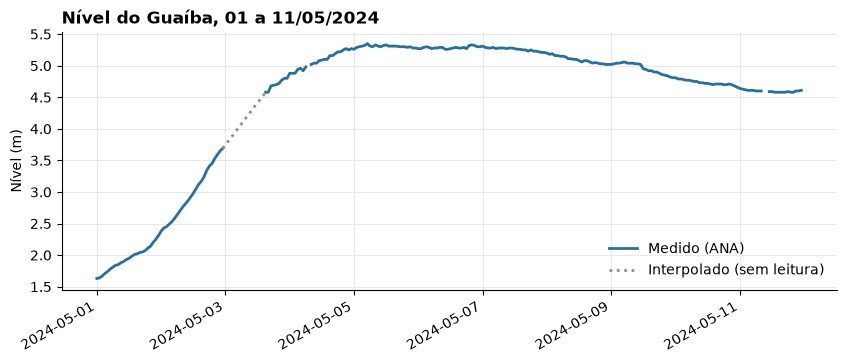

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
m = h[h.origem == 'medido']; i = h[h.nivel_cm.index.isin(h.index[(h.origem=='interpolado')]) ]
ax.plot(h.data_hora, h.nivel_m.where((h.origem == 'medido')), color=AZUL, lw=2, label='Medido (ANA)')
g = h[(h.data_hora >= '2024-05-02 23:00') & (h.data_hora <= '2024-05-03 15:00')]
ax.plot(g.data_hora, g.nivel_m, color=CINZA, lw=2, ls=':', label='Interpolado (sem leitura)')
ax.legend(frameon=False, loc='lower right'); ax.set(title='Nível do Guaíba, 01 a 11/05/2024', ylabel='Nível (m)')
fig.autofmt_xdate(); h.loc[h.nivel_m.idxmax(), ['data_hora', 'nivel_m', 'estacao']]

O rio passou da cota em 02/05 e chegou ao pico em 05/05. Há 18 horas interpoladas entre as estações, marcadas no gráfico e na coluna `origem`. Nelas muda a estação e o referencial, então o desenho da subida é aproximado.

### 9. Maiores cheias × pessoas afetadas pela simulação (ligação com a Tela 1)

,data,estacao,nivel_max_cm,nivel_inct,pessoas
2931,2023-09-27,Cais Mauá,318.0,3.2,40469
2982,2023-11-21,Cais Mauá,346.0,3.5,56027
3148,2024-05-05,Usina do Gasômetro,535.0,5.4,139179
3564,2025-06-25,Cais Mauá,301.0,3.0,32112


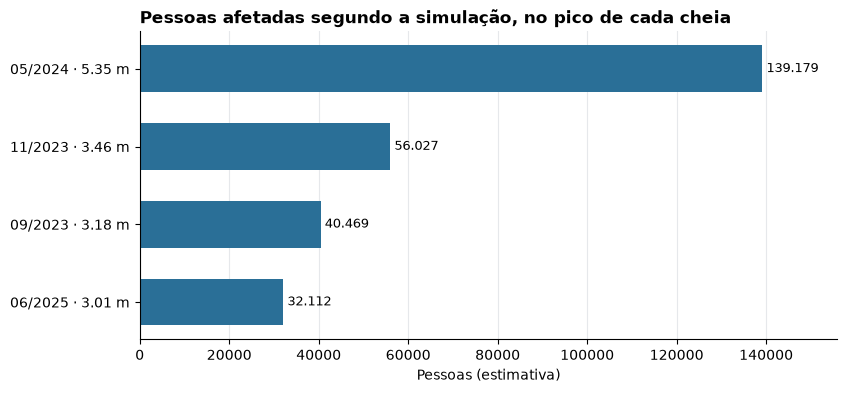

In [10]:
a = ana[ana.acima_cota].copy()
a['evento'] = (a.data.diff().dt.days > 5).cumsum()
ev = a.loc[a.groupby('evento').nivel_max_cm.idxmax(), ['data', 'estacao', 'nivel_max_cm']].copy()
ev['nivel_inct'] = np.floor(ev.nivel_max_cm/10 + .5)/10
ev = ev.join(cidade.pessoas, on='nivel_inct').sort_values('pessoas')
fig, ax = plt.subplots()
l = ev.data.dt.strftime('%m/%Y') + ' · ' + (ev.nivel_max_cm/100).map('{:.2f} m'.format)
ax.barh(l, ev.pessoas, color=AZUL, height=.6)
for y, v in zip(l, ev.pessoas): ax.text(v, y, f' {v:,.0f}'.replace(',', '.'), va='center', fontsize=9)
ax.set(title='Pessoas afetadas segundo a simulação, no pico de cada cheia', xlabel='Pessoas (estimativa)'); ax.grid(axis='y', visible=False); ax.margins(x=.12)
ev.sort_values('data')

Cada nível real da ANA é arredondado ao décimo e consultado na simulação. É uma estimativa do que aquele nível representaria hoje, não uma contagem de quem foi atingido. Enquanto o INCT não confirmar o referencial da simulação, a comparação entre estações é aproximada.

### 10. Pessoas afetadas estimadas ao longo da enchente

np.float64(139179.0)

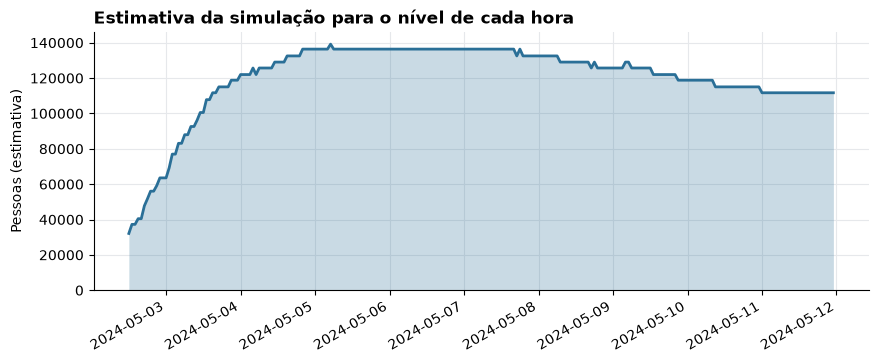

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
d = h.dropna(subset=['pessoas_estimadas'])
ax.fill_between(d.data_hora, d.pessoas_estimadas, color=AZUL, alpha=.25, lw=0); ax.plot(d.data_hora, d.pessoas_estimadas, color=AZUL, lw=2)
ax.set(title='Estimativa da simulação para o nível de cada hora', ylabel='Pessoas (estimativa)', ylim=(0, None)); fig.autofmt_xdate()
d.pessoas_estimadas.max()

Este é o gráfico que alimenta a linha do tempo da Tela 2. A estimativa supõe população igual em todos os prédios, inclusive não residenciais, e só depende do nível do rio. Ela não considera diques, comportas ou casas de bomba, cuja falha teve papel central em 2024.